# Auto MPG Degree-2 Polynomial Regression — Adam Optimizer (Adaptive Moment Estimation)

## 1. Project Objective and Optimizer Introduction
The objective of this notebook is to predict vehicle fuel efficiency (`mpg`) from engine `horsepower` using degree-2 Polynomial Regression ($\hat{y} = w_0 + w_1 z_1 + w_2 z_2$, where $z_1, z_2$ are standardized $x$ and $x^2$ features). Adam (Adaptive Moment Estimation) inherently integrates momentum by maintaining an exponentially decaying moving average of past gradients (first moment $m_t$, momentum) and squared gradients (second moment $v_t$, RMSprop), computing bias-corrected estimates $\hat{m}_t = \frac{m_t}{1 - \beta_1^t}$ and $\hat{v}_t = \frac{v_t}{1 - \beta_2^t}$, and updating parameters via $w_t = w_{t-1} - \eta \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$, with $\beta_1 = 0.9$, $\beta_2 = 0.999$, and $\epsilon = 10^{-8}$.

## 2. Imports and Dataset Loading
We import NumPy, pandas, Matplotlib, and scikit-learn preprocessing/splitting utilities, then load the shared local `auto-mpg.csv` dataset via a portable relative path. If `auto-mpg.csv` is missing locally, it is downloaded automatically via `kagglehub`.

In [1]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

csv_path = "auto-mpg.csv"
if not os.path.exists(csv_path):
    import kagglehub
    path = kagglehub.dataset_download("uciml/autompg-dataset")
    shutil.copy2(os.path.join(path, "auto-mpg.csv"), csv_path)

raw_df = pd.read_csv(csv_path)
print(f"Loaded '{csv_path}' with {len(raw_df)} initial rows.")

Loaded 'auto-mpg.csv' with 398 initial rows.


## 3. Data Cleaning and Train/Validation/Test Split
We retain only `horsepower` and `mpg`, coerce non-numeric strings such as `"?"` to `NaN`, drop rows with missing values, and remove exact duplicate `(horsepower, mpg)` pairs. The remaining 332 unique pairs are split into approximately 70% training (232), 15% validation (50), and 15% test (50) using `random_state=42`.

In [2]:
df = raw_df[["horsepower", "mpg"]].copy()
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["mpg"] = pd.to_numeric(df["mpg"], errors="coerce")

df_no_missing = df.dropna(subset=["horsepower", "mpg"])
df_clean = df_no_missing.reset_index(drop=True)

X_raw = df_clean[["horsepower"]].values
y_raw = df_clean["mpg"].values

X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=42
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42
)

print(f"Rows after dropping missing values: {len(df_no_missing)}")
print(f"Rows retained for modeling (no valid observations deduplicated): {len(df_clean)}")
print(f"Split sizes -> Training: {len(y_train)}, Validation: {len(y_val)}, Test: {len(y_test)}")

Rows after dropping missing values: 392
Rows retained for modeling (no valid observations deduplicated): 392
Split sizes -> Training: 274, Validation: 59, Test: 59


## 4. Degree-2 Polynomial Features and Scaling
We expand `horsepower` ($x$) into degree-2 polynomial features $[x, x^2]$ and standardize both feature columns using **training-split statistics only** to prevent data leakage. A column of ones is prepended as a separate intercept term $w_0$, yielding design matrices of shape `(n_samples, 3)`.

In [3]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_raw)
X_val_poly = poly.transform(X_val_raw)
X_test_poly = poly.transform(X_test_raw)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_val_scaled = scaler.transform(X_val_poly)
X_test_scaled = scaler.transform(X_test_poly)

def add_intercept(X_scaled):
    return np.column_stack([np.ones(X_scaled.shape[0]), X_scaled])

X_train = add_intercept(X_train_scaled)
X_val = add_intercept(X_val_scaled)
X_test = add_intercept(X_test_scaled)

print(f"Training design matrix shape: {X_train.shape}")
print(f"Training feature means (x, x²): {np.round(scaler.mean_, 2)}")

Training design matrix shape: (274, 3)
Training feature means (x, x²): [  104.88 12449.42]


## 5. Model, MSE Loss, and Gradient
Given design matrix $X = [1, z_1, z_2]$ and weight vector $w = [w_0, w_1, w_2]^T$, predictions are $\hat{y} = X w$ in original `mpg` units. Mean Squared Error is $\text{MSE} = \frac{1}{m} \sum_{i=1}^m (\hat{y}_i - y_i)^2$, and its analytic gradient with respect to $w$ is $g = \frac{2}{m} X^T (\hat{y} - y)$.

In [4]:
def predict(X, w):
    return X @ w

def compute_mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))

def compute_gradients(X_batch, y_batch, w):
    errors = predict(X_batch, w) - y_batch
    return (2.0 / len(y_batch)) * (X_batch.T @ errors)

## 6. Manual Optimizer Implementation
Adam initializes `w`, first-moment vector `m` (momentum), and second-moment vector `v` to zeros and increments the update counter `t` on every mini-batch step so bias correction ($1 - \beta_1^t$ and $1 - \beta_2^t$) is applied at every parameter update. Training runs for `epochs = 250` with `batch_size = 32` (including the final partial batch of 8 samples) and `seed = 42`, recording end-of-epoch training and validation MSE and returning final-epoch weights.

In [5]:
def train_adam(X_tr, y_tr, X_va, y_va, lr, epochs=250, batch_size=32, beta1=0.9, beta2=0.999, eps=1e-8, seed=42):
    w = np.zeros(X_tr.shape[1], dtype=float)
    m = np.zeros_like(w)
    v = np.zeros_like(w)
    t = 0
    rng = np.random.default_rng(seed)
    train_mse_history = []
    val_mse_history = []

    for _ in range(epochs):
        indices = rng.permutation(len(y_tr))
        for start in range(0, len(y_tr), batch_size):
            batch_idx = indices[start : start + batch_size]
            X_b = X_tr[batch_idx]
            y_b = y_tr[batch_idx]
            grad = compute_gradients(X_b, y_b, w)
            t += 1
            m = beta1 * m + (1.0 - beta1) * grad
            v = beta2 * v + (1.0 - beta2) * (grad ** 2)
            m_hat = m / (1.0 - beta1 ** t)
            v_hat = v / (1.0 - beta2 ** t)
            w = w - lr * m_hat / (np.sqrt(v_hat) + eps)

        train_mse_history.append(compute_mse(y_tr, predict(X_tr, w)))
        val_mse_history.append(compute_mse(y_va, predict(X_va, w)))

    # Policy: Return final-epoch weights (no early stopping or checkpointing).
    return w, train_mse_history, val_mse_history

## 7. Training and Learning-Rate Selection
We train Adam across the candidate learning-rate grid `[0.001, 0.005, 0.01, 0.05, 0.1]` for 250 epochs each with `batch_size = 32`. Hyperparameter selection uses **final-epoch Validation MSE only**, keeping the test split untouched until final evaluation.

In [6]:
lr_candidates = [0.001, 0.005, 0.01, 0.05, 0.1]
optimizer_name = "Adam"

best_val_mse = float("inf")
best_run = None
search_rows = []

for lr in lr_candidates:
    w_final, tr_hist, va_hist = train_adam(X_train, y_train, X_val, y_val, lr=lr, epochs=250)
    val_mse = va_hist[-1]
    search_rows.append({"Learning Rate": lr, "Final Training MSE": round(tr_hist[-1], 4), "Final Validation MSE": round(val_mse, 4)})
    if np.isfinite(val_mse) and val_mse < best_val_mse:
        best_val_mse = val_mse
        best_run = {
            "lr": lr,
            "w": w_final,
            "val_mse": val_mse,
            "train_history": tr_hist,
            "val_history": va_hist,
        }

selected_weights = best_run["w"]
print(f"Selected learning rate for {optimizer_name} (by Validation MSE): {best_run['lr']}")
print(f"Final-epoch weights [w0, w1, w2]: {np.round(selected_weights, 4)}")
pd.DataFrame(search_rows)

Selected learning rate for Adam (by Validation MSE): 0.1
Final-epoch weights [w0, w1, w2]: [ 23.6501 -17.5176  11.3745]


,Learning Rate,Final Training MSE,Final Validation MSE
0,0.001,495.0068,475.4493
1,0.005,209.9317,195.8837
2,0.010,65.3265,59.7281
3,0.050,19.9707,22.0842
4,0.100,18.6486,21.5061


## 8. Evaluation and Visualizations
We evaluate the selected final-epoch model across the `Training`, `Validation`, and `Test` splits in original `mpg` units, reporting MSE (`mpg²`), RMSE (`mpg`), and $R^2$ for each split. We then plot the training and validation MSE learning curve across epochs and the degree-2 polynomial prediction curve over sorted `horsepower` values alongside the observed data points.

In [7]:
split_records = []
for split_name, X_s, y_s in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    preds = predict(X_s, selected_weights)
    mse_val = float(mean_squared_error(y_s, preds))
    rmse_val = float(np.sqrt(mse_val))
    mae_val = float(np.mean(np.abs(y_s - preds)))
    r2_val = float(r2_score(y_s, preds))
    split_records.append(
        {
            "Optimizer": optimizer_name,
            "Learning Rate": best_run["lr"],
            "Evaluated Split": split_name,
            "MSE (mpg²)": round(mse_val, 4),
            "RMSE (mpg)": round(rmse_val, 4),
            "MAE (mpg)": round(mae_val, 4),
            "R²": round(r2_val, 4),
        }
    )

evaluation_df = pd.DataFrame(split_records)
evaluation_df

,Optimizer,Learning Rate,Evaluated Split,MSE (mpg²),RMSE (mpg),MAE (mpg),R²
0,Adam,0.1,Training,18.6486,4.3184,3.1968,0.7087
1,Adam,0.1,Validation,21.5061,4.6375,3.3445,0.6154
2,Adam,0.1,Test,18.9974,4.3586,3.5124,0.6156


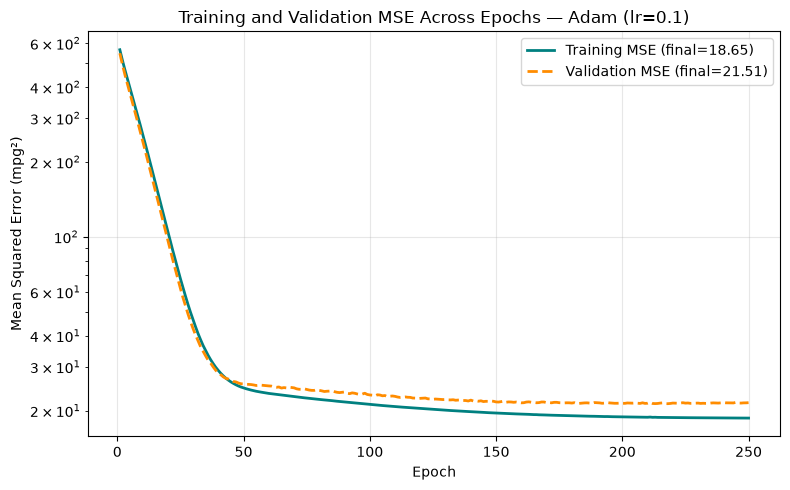

In [8]:
epochs_axis = range(1, len(best_run["train_history"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs_axis,
    best_run["train_history"],
    label=f"Training MSE (final={best_run['train_history'][-1]:.2f})",
    color="teal",
    linewidth=2.0,
)
plt.plot(
    epochs_axis,
    best_run["val_history"],
    label=f"Validation MSE (final={best_run['val_history'][-1]:.2f})",
    color="darkorange",
    linestyle="--",
    linewidth=2.0,
)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (mpg²)")
plt.title(f"Training and Validation MSE Across Epochs — {optimizer_name} (lr={best_run['lr']})")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

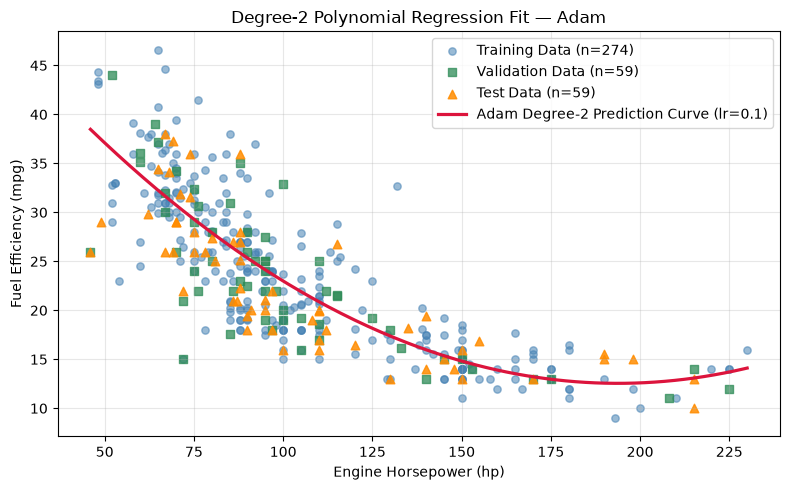

In [9]:
hp_sorted = np.linspace(df_clean["horsepower"].min(), df_clean["horsepower"].max(), 200).reshape(-1, 1)
hp_sorted_poly = poly.transform(hp_sorted)
hp_sorted_scaled = scaler.transform(hp_sorted_poly)
hp_sorted_design = add_intercept(hp_sorted_scaled)
mpg_pred_curve = predict(hp_sorted_design, selected_weights)

plt.figure(figsize=(8, 5))
plt.scatter(X_train_raw[:, 0], y_train, alpha=0.55, label=f"Training Data (n={len(y_train)})", color="steelblue", s=28)
plt.scatter(X_val_raw[:, 0], y_val, alpha=0.75, label=f"Validation Data (n={len(y_val)})", color="seagreen", marker="s", s=32)
plt.scatter(X_test_raw[:, 0], y_test, alpha=0.85, label=f"Test Data (n={len(y_test)})", color="darkorange", marker="^", s=38)
plt.plot(
    hp_sorted[:, 0],
    mpg_pred_curve,
    color="crimson",
    linewidth=2.3,
    label=f"{optimizer_name} Degree-2 Prediction Curve (lr={best_run['lr']})",
)
plt.xlabel("Engine Horsepower (hp)")
plt.ylabel("Fuel Efficiency (mpg)")
plt.title(f"Degree-2 Polynomial Regression Fit — {optimizer_name}")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Conclusion
Adam completed the experiment using **392 valid Auto MPG observations** (Training: 274, Validation: 59, Test: 59). The learning rate selected using the final-epoch validation MSE was `0.1`. Validation MSE: `21.5061` mpg². On the held-out test set: MSE = `18.9974` mpg², RMSE = `4.3586` mpg, MAE = `3.5124` mpg, and R² = `0.6156`.

**Interpretation caution:** The experiment retains all 392 valid observations; no records are removed merely because they share `(horsepower, mpg)` values. Equal epoch counts do not imply equal optimizer steps or computational costs. Momentum improvements over a non-momentum baseline and statistical superiority have not been established. Learning rates are selected using validation data, not the test set.